找到的文件：
   FC1_Ageing_part1.csv
   FC1_Ageing_part2.csv
   FC1_Ageing_part3.csv
读入 FC1_Ageing_part1.csv，形状 (65535, 25)
读入 FC1_Ageing_part2.csv，形状 (65535, 25)
读入 FC1_Ageing_part3.csv，形状 (12792, 25)
训练集大小： (115089, 1)
测试集大小： (28773, 1)

线性回归结果：
训练集 RMSE = 0.009139 V
测试集 RMSE = 0.031754 V
训练集 MAE  = 0.007203 V
测试集 MAE  = 0.028293 V
斜率 = -0.00014105 V/h
截距 = 3.3422 V


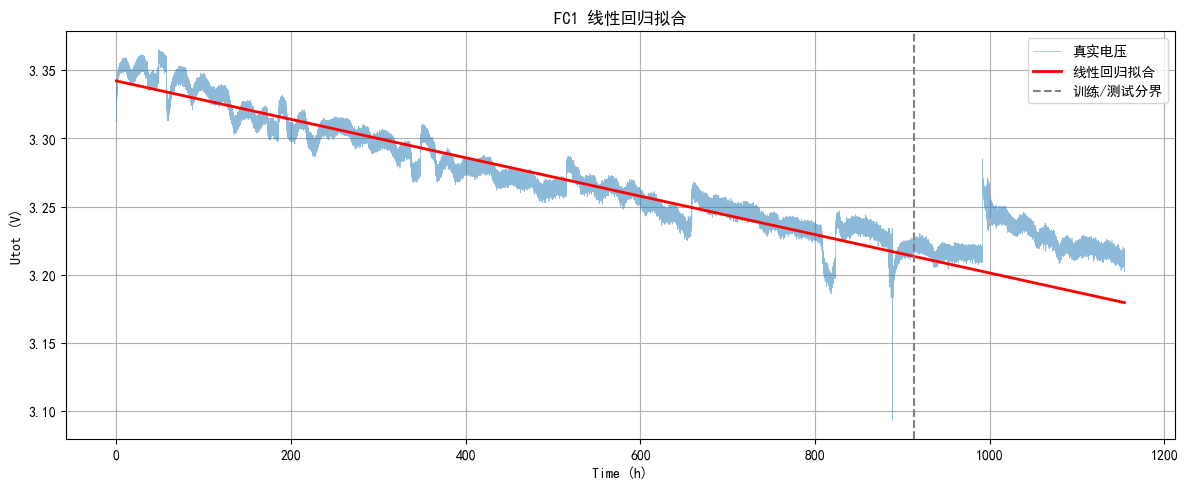

模型对比（测试集）
线性回归  RMSE = 0.031754 V   MAE = 0.028293 V
随机森林  RMSE = 0.012309 V   MAE = 0.008519 V

RMSE 下降幅度：61.24%

随机森林特征重要性：
  Time (h): 0.9963
  ToutH2 (°C): 0.0018
  HrAIRFC (%): 0.0011
  I (A): 0.0009


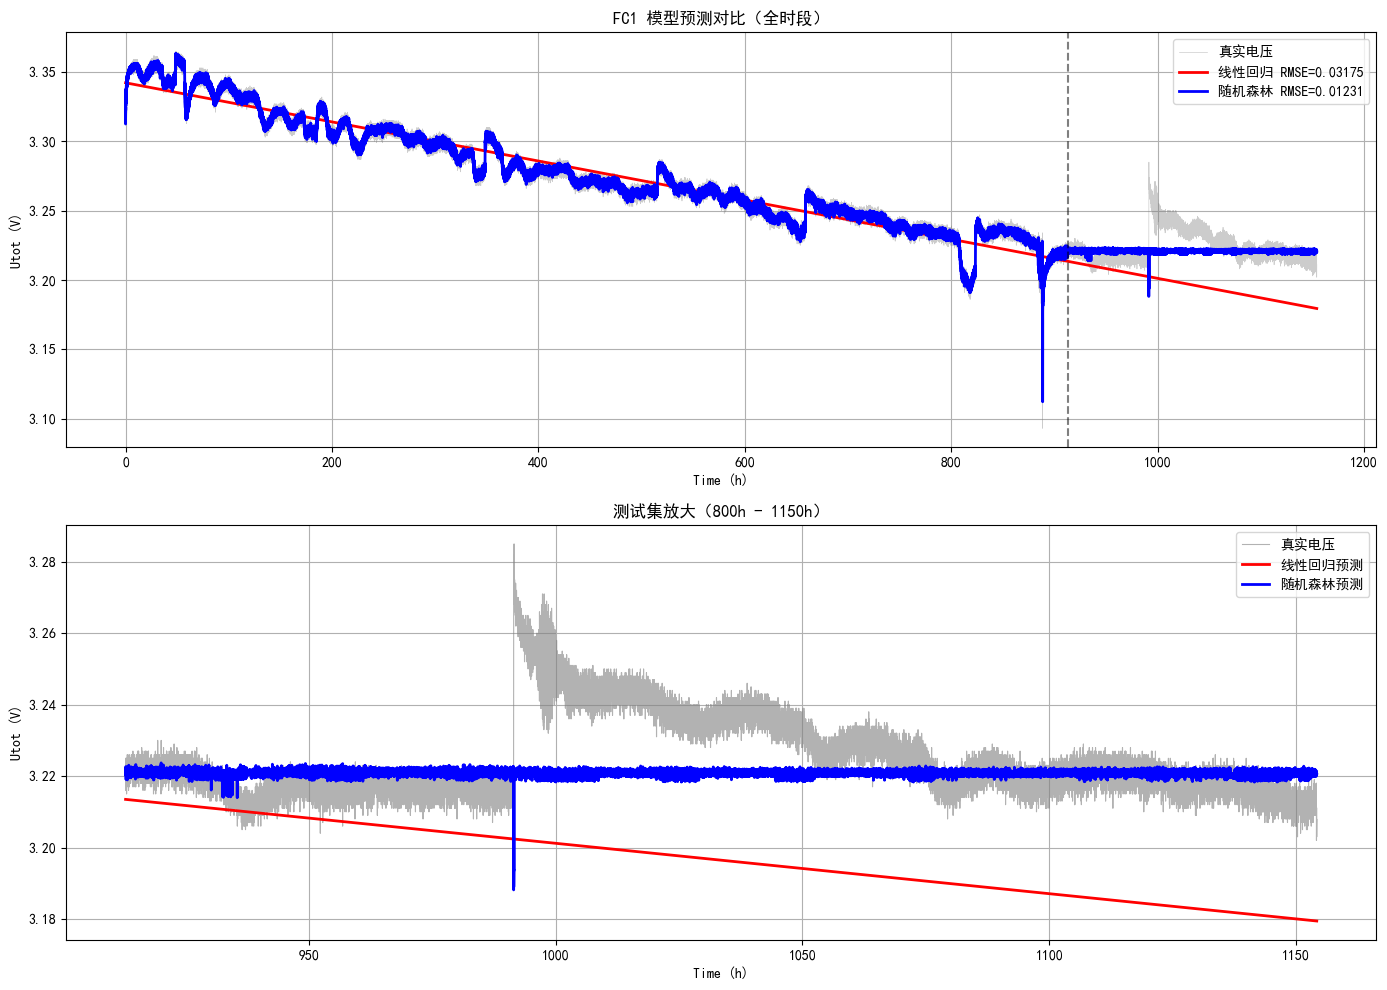

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
from sklearn.linear_model import LinearRegression#从线性模型里拿出线性回归
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
#sklearn是百宝箱
#LinearRegression（线性回归）画直线
#RandomForestRegressor（随机森林回归）决策树分析
#mean_squared_error（均方误差，MSE）和 mean_absolute_error（平均绝对误差，MAE）
#我们在代码里通常会把MSE开根号（np.sqrt(mean_squared_error)），这就变成了大名鼎鼎的 RMSE（均方根误差）

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 读入之前存好的完整数据
folder = r'C:\Users\YOGA\Desktop\电池ai分析\IEEE2014DataChallengeData\IEEE 2014 Data Challenge Data\FC1_Without_Ripples\csv 1'
files = glob.glob(os.path.join(folder, '*.csv'))
print("找到的文件：")
for f in files:
    print("  ", os.path.basename(f))
dfs = []   #dfs = []：建一个空列表，准备装三个 DataFrame。
for f in files:#for f in files：意思是：“对于 files 里面的每一个东西，我都挨个拿出来，取个外号叫 f，然后执行下面的操作。” 一直循环到列表里没有东西为止。
    temp = pd.read_csv(f, encoding='latin1')#encoding='latin1'万能兼容大法
    dfs.append(temp)#.append() 就是“插队到最后一个”。
    print(f"读入 {os.path.basename(f)}，形状 {temp.shape}")

df = pd.concat(dfs, ignore_index=True)
df = df.sort_values('Time (h)').reset_index(drop=True)


# ---- 准备特征和目标 ----
# 特征：只用时间
X = df[['Time (h)']].values
# 目标：总电压
y = df['Utot (V)'].values

# ---- 划分训练集和测试集 ----
# 前 80% 训练，后 20% 测试
split_idx = int(len(df) * 0.8)#int是高斯函数，向下取整，int作用就是去小数
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

print("训练集大小：", X_train.shape)
print("测试集大小：", X_test.shape)

# ---- 训练线性回归 ----
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)#.fit是在学习

# ---- 预测 ----
y_pred_train = model_lr.predict(X_train)#.predict在预测
y_pred_test = model_lr.predict(X_test)#train、test训练集要预测一遍，看一下是不是蠢猪模型，没错，模型可能是智障。

# ---- 算误差 ----
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
mae_train = mean_absolute_error(y_train, y_pred_train)
mae_test = mean_absolute_error(y_test, y_pred_test)

print("\n线性回归结果：")
print(f"训练集 RMSE = {rmse_train:.6f} V")
print(f"测试集 RMSE = {rmse_test:.6f} V")
print(f"训练集 MAE  = {mae_train:.6f} V")
print(f"测试集 MAE  = {mae_test:.6f} V")
print(f"斜率 = {model_lr.coef_[0]:.8f} V/h")
print(f"截距 = {model_lr.intercept_:.4f} V")

# ---- 画图 ----
plt.figure(figsize=(12, 5))
plt.plot(df['Time (h)'], y, linewidth=0.5, alpha=0.5, label='真实电压')
plt.plot(df['Time (h)'], model_lr.predict(X), linewidth=2, color='red', label='线性回归拟合')
#model_lr.predict(X) 的意思是：“用训练好的模型，把从古至今所有的时间点都预测一遍。
plt.axvline(df['Time (h)'].iloc[split_idx], color='gray', linestyle='--', label='训练/测试分界')
#.ax（坐标轴）vline就是“画一条垂直线”。 #.iloc = integer location（按整数位置取数据）
plt.xlabel('Time (h)')
plt.ylabel('Utot (V)')
plt.title('FC1 线性回归拟合')
plt.legend()
plt.grid(True)
plt.tight_layout()
#plt.savefig(r'C:\Users\YOGA\Desktop\训练1.png', dpi=300, bbox_inches='tight')
plt.show()

#总结一下机器学习的“四大金刚”动作：
#model.fit(X_train, y_train)：学习（用前 80% 的数据找规律）。
#model.predict(X_train)：预测训练集（看看自己练熟的题能不能做对）。
#model.predict(X_test)：预测测试集（看看没见过的题能不能做对）。
#model.predict(X)：全量预测（为了画出一条贯穿全程的漂亮曲线）。
#这下是不是感觉通透多了？

# ========== 2. 准备特征 ==========
# 线性回归只用时间（保持之前的对照）
X_lr = df[['Time (h)']].values
# 随机森林用时间 + 温度 + 湿度（多特征）
X_rf = df[['Time (h)', 'ToutH2 (°C)', 'HrAIRFC (%)', 'I (A)']].values
y = df['Utot (V)'].values

# ========== 3. 划分训练/测试 ==========
split_idx = int(len(df) * 0.8)
X_lr_train, X_lr_test = X_lr[:split_idx], X_lr[split_idx:]
X_rf_train, X_rf_test = X_rf[:split_idx], X_rf[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

# ========== 4. 训练两个模型 ==========
model_lr = LinearRegression()
model_lr.fit(X_lr_train, y_train)

model_rf = RandomForestRegressor(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
#n_estimators=100：种 100 棵树。
#max_depth=20：每棵树最深只能问 20 个问题。
#random_state=42：随机种子。
#n_jobs=-1：用满你的 CPU。-1 意思是调用电脑所有的核心去并行计算，算得快一点。
model_rf.fit(X_rf_train, y_train)

# ========== 5. 预测 ==========
y_pred_lr = model_lr.predict(X_lr)
y_pred_rf = model_rf.predict(X_rf)

# ========== 6. 算误差（只在测试集上算） ==========
def metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    return rmse, mae
#你发现没有，算 RMSE 和 MAE 的代码，在训练集要写一遍，测试集又要写一遍。太啰嗦了！
#所以你打包了一个叫 metrics 的“加工厂”：只要你把真实值（y_true）和预测值（y_pred）丢进去，它就在里面算好，然后把两个分数吐出来。这叫封装，是为了偷懒且不出错。

rmse_lr, mae_lr = metrics(y_test, y_pred_lr[split_idx:])
rmse_rf, mae_rf = metrics(y_test, y_pred_rf[split_idx:])

print("=" * 50)
print("模型对比（测试集）")
print("=" * 50)
print(f"线性回归  RMSE = {rmse_lr:.6f} V   MAE = {mae_lr:.6f} V")# {rmse_lr:.6f}留六位小数
print(f"随机森林  RMSE = {rmse_rf:.6f} V   MAE = {mae_rf:.6f} V")
print(f"\nRMSE 下降幅度：{(rmse_lr - rmse_rf) / rmse_lr * 100:.2f}%")

# ========== 7. 随机森林特征重要性 ==========
feature_names = ['Time (h)', 'ToutH2 (°C)', 'HrAIRFC (%)', 'I (A)']
importances = model_rf.feature_importances_
print("\n随机森林特征重要性：")
for name, imp in sorted(zip(feature_names, importances), key=lambda x: -x[1]):#把特征重要性从大到小排个序
    print(f"  {name}: {imp:.4f}")
#zip(feature_names, importances)：把“特征名字”和“重要性数值”像拉链一样扣在一起。变成 [('Time', 0.99), ('ToutH2', 0.001)...]。
#key=lambda x: -x[1]：这是排序的规则。x[1] 指的是每个元组的第二个元素（也就是重要性数值）。前面加个负号 -，表示降序排列（从大到小）。
#for name, imp in ...：排好序后，挨个拿出来，name 是名字，imp 是数值，打印出来。
#如果没有这行代码（for），你的输出就是乱序的，你根本不知道哪个特征排第一。

# ========== 8. 画图对比 ==========
fig, axes = plt.subplots(2, 1, figsize=(14, 10))
#fig表示大画布，大背景
#subplots（行，列，大小）
#axes[第几块画布]


# 上图：两个模型 vs 真实
axes[0].plot(df['Time (h)'], y, linewidth=0.5, alpha=0.4, color='gray', label='真实电压')
axes[0].plot(df['Time (h)'], y_pred_lr, linewidth=2, color='red', label=f'线性回归 RMSE={rmse_lr:.5f}')
axes[0].plot(df['Time (h)'], y_pred_rf, linewidth=2, color='blue', label=f'随机森林 RMSE={rmse_rf:.5f}')
axes[0].axvline(df['Time (h)'].iloc[split_idx], color='black', linestyle='--', alpha=0.5)
axes[0].set_xlabel('Time (h)')
axes[0].set_ylabel('Utot (V)')
axes[0].set_title('FC1 模型预测对比（全时段）')
axes[0].legend()
axes[0].grid(True)

# 下图：只看测试集
axes[1].plot(df['Time (h)'].iloc[split_idx:], y_test, linewidth=0.8, alpha=0.6, color='gray', label='真实电压')
axes[1].plot(df['Time (h)'].iloc[split_idx:], y_pred_lr[split_idx:], linewidth=2, color='red', label='线性回归预测')
axes[1].plot(df['Time (h)'].iloc[split_idx:], y_pred_rf[split_idx:], linewidth=2, color='blue', label='随机森林预测')
axes[1].set_xlabel('Time (h)')
axes[1].set_ylabel('Utot (V)')
axes[1].set_title('测试集放大（800h - 1150h）')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
#plt.savefig(r'C:\Users\YOGA\Desktop\FC1_model_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

# ========== 9. 保存结果表格 ==========
results = pd.DataFrame({
    '模型': ['线性回归', '随机森林'],
    '特征': ['Time only', 'Time + ToutH2 + HrAIRFC + I'],
    'RMSE (V)': [rmse_lr, rmse_rf],
    'MAE (V)': [mae_lr, mae_rf]
})
#results.to_csv(r'C:\Users\YOGA\Desktop\FC1_baseline_results.csv', index=False, encoding='utf-8-sig')
#print("\n结果已保存到桌面：FC1_baseline_results.csv")
#print("图片已保存到桌面：FC1_model_comparison.png")

#RMSE（均方根误差）：预测值和真实值之差的平方，取平均，再开根号。单位是伏特。对大误差敏感——如果模型偶尔错得很离谱，RMSE 会明显变大。越小越好。

#MAE（平均绝对误差）：预测值和真实值之差的绝对值，取平均。单位是伏特。对每个误差一视同仁——不管错得大还是小，都按绝对值算。越小越好。

#两个一起看：RMSE 和 MAE 差距越大，说明模型存在“偶尔错得很离谱”的情况。你的随机森林 RMSE=0.0123、MAE=0.0085，差距不大，说明误差分布比较均匀，没有极端离群。

#特征重要性：随机森林训练完之后，会输出每个特征对预测的贡献比例，加起来等于 1。值越大，说明这个特征越重要。

In [4]:
#初代LSTM
import numpy as np
import pandas as pd
import torch#（张量）：在 PyTorch 里，所有数据都必须转成 Tensor 才能喂给模型。它会用GPU，有自动求导机制
#可以这么理解：模型在猜结果（比如猜电压是 3.2V），真实值是 3.3V。误差就是差的那 0.1V。
#模型内部有无数个旋钮（参数）。自动求导（Autograd）就像是一个“找方向仪”。它通过微积分里的“链式法则”，自动算出：“如果我调高A旋钮，误差是变大还是变小？调低B旋钮，误差会怎么变？”
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler#（归一化）
#神经网络就像个“极其挑剔的机器”。
#电压是 3.3V，时间是 1000小时，温度是 60℃。如果不做处理直接丢给神经网络，它会因为数字太大，导致内部的计算爆炸（专业叫“梯度爆炸”），根本学不会。
#归一化就是“把所有数据按比例压缩到 0 到 1 之间”。公式很简单：(当前值 - 最小值) / (最大值 - 最小值)。
import matplotlib.pyplot as plt
#算完之后，优化器（Optimizer）就会顺着“误差变小的方向”去拧这些旋钮。这就是模型学习的本质。

# 假设 df 已经是你读好的 FC1 数据表
# 1. 提取我们要的列（先用单变量电压试试水）
data = df['Utot (V)'].values.reshape(-1, 1)#提取数字，变为-1行（不存在，让机子自己算），1列
#加上 .values，就是把这列数据剥掉“Excel外衣”，变成纯纯的 NumPy 数组（类似于 [3.3, 3.31, 3.29...]）。神经网络不认 pandas 格式，只认纯数字数组。
#变成 (-1, 1) 的意思是：变成 1 列，行数让电脑自己算（-1 就代表自动推算）。

# 2. 归一化（训练技巧：神经网络对数字大小极度敏感，3.3V 进去容易梯度爆炸，变成 0-1 之间最好）
scaler = MinMaxScaler(feature_range=(0, 1))#scaler：归一化
#这行代码只是定义了这个“0~1”压缩工具，还没有真正去压缩数据。
data_scaled = scaler.fit_transform(data)#之所以叫 _scaled，只是为了方便程序员看懂
#scaler归一化；fit：计算数据的最大值和最小值；transform：把所有数字套进公式 (当前值 - 最小值) / (最大值 - 最小值)。

# 3. 构建滑动窗口（核心逻辑！）
def create_sequences(data, seq_length):#假设数据是：[10, 20, 30, 40, 50, 60]，seq_length = 3（用过去 3 个预测第 4 个）。
    xs = []
    ys = []
    for i in range(len(data) - seq_length):
        # x 是过去 seq_length 天的数据
        x = data[i : i + seq_length]
        # y 是紧接着的下一天的数据
        y = data[i + seq_length]
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

SEQ_LENGTH = 24 # 用过去 24 个点预测下一个点
X_lstm, y_lstm = create_sequences(data_scaled, SEQ_LENGTH)#create_sequences这个厨子拿着SEQ_LENGTH去划拉data_scaled，划拉的历史是X_lstm，划拉出的未来是y_lstm（一个）

# 4. 划分训练集和测试集（必须按时间顺序！80% 训练）
train_size = int(len(X_lstm) * 0.8)
X_train_lstm, X_test_lstm = X_lstm[:train_size], X_lstm[train_size:]
y_train_lstm, y_test_lstm = y_lstm[:train_size], y_lstm[train_size:]

# 5. 转成 PyTorch 专属的张量 (Tensor)
# LSTM 要求的形状：(Batch_Size, Sequence_Length, Features)
X_train_tensor = torch.FloatTensor(X_train_lstm)
y_train_tensor = torch.FloatTensor(y_train_lstm)
X_test_tensor = torch.FloatTensor(X_test_lstm)
y_test_tensor = torch.FloatTensor(y_test_lstm)
#torch.FloatTensor：把 Numpy 数组变成 PyTorch 能吃的、带小数的高精度张量（Tensor）矩阵。

print("X_train 形状:", X_train_tensor.shape) # 应该是 [52000多, 24, 1]
print("y_train 形状:", y_train_tensor.shape) # 应该是 [52000多, 1]

X_train 形状: torch.Size([115070, 24, 1])
y_train 形状: torch.Size([115070, 1])


In [6]:
# 定义 LSTM 模型
class VoltageLSTM(nn.Module):# 定义一个名为 VoltageLSTM 的类，它继承自 nn.Module（这是 PyTorch 所有神经网络的祖师爷）
    def __init__(self, input_size=1, hidden_size=48, num_layers=2, output_size=1):
        # input_size=1 (输入特征数：旧版只吃电压)，hidden_size=64 (隐藏层神经元个数，即脑容量)，num_layers=2 (层数)，output_size=1 (输出1个电压值)
        # 必须加这一句，初始化父类，相当于给祖师爷上香，让整个网络框架生效
        # 初始化函数（配置单）
        super(VoltageLSTM, self).__init__()#VoltageLSTM：是给这个神经网络起类名，self：就是“我自己”。在代码里，新创建的 model 就是个孩子，self 就是用来指代这个孩子的。super(...)：意思是“找我的爸爸”。
        #这句话的意思是：“去把我爸爸（PyTorch 的祖宗类 nn.Module）叫醒，把它的初始化配置全盘继承过来。” 这是 PyTorch 里写网络极其固定的八股文，死记硬背即可。
        # 1. LSTM 层（核心层）
        # input_size=1 (只输入电压), hidden_size=64 (大脑里记 64 个特征，越多越聪明也越容易过拟合)
        # num_layers=2 (两层叠起来，学习更深的规律)
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)#self.lstm：告诉自己“给我装一个 LSTM 引擎”。
        # [Batch（样本数/行），Seq（时间步长/列），Features（特征数）]
        # batch_first=True 就是告诉 PyTorch，我给你的三维数据顺序是：[样本数, 时间步长, 特征数]。
        # batch_first=True 非常重要：告诉 PyTorch，我喂给你的数据，第 0 维是样本数(batch)，第 1 维是时间步(seq)
        # 2. 全连接层（把 LSTM 记住的东西，翻译成我们想要的 1 个预测数值）
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # x 的形状是 (batch_size, seq_length, features)
        # out 包含了所有时间步的输出，_ 是隐藏状态（我们这里不需要用它）
        out, _ = self.lstm(x)

        # 我们只关心最后一个时间步（即第 24 个点）推导出来的结果
        # out[:, -1, :] 的意思就是取所有 batch 的最后一个序列的输出
        out = self.fc(out[:, -1, :])# out[:, -1, :] 这个切片的意思是：取所有行(:)，取最后一列时间步(-1)，取所有的特征(:)
        return out

# 实例化模型
model = VoltageLSTM()
print(model)

VoltageLSTM(
  (lstm): LSTM(1, 48, num_layers=2, batch_first=True)
  (fc): Linear(in_features=48, out_features=1, bias=True)
)


Epoch [10/15], Loss: 0.180104


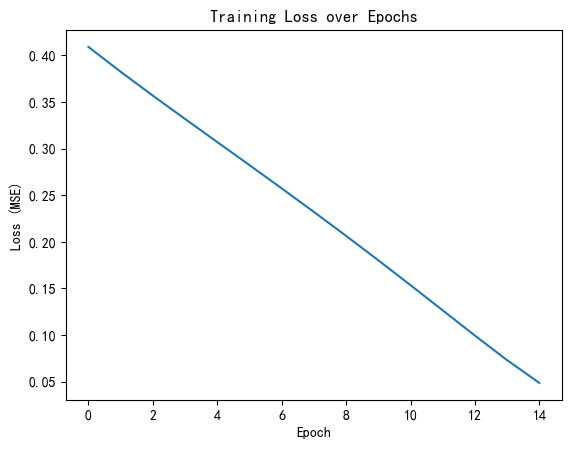

In [7]:
 # 1. 定义损失函数和优化器
criterion = nn.MSELoss() # 均方误差（之前我们讲过的那个）
# Adam 是最好用的优化器。lr=0.001 是学习率（步子迈多大）
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# 2. 开始训练
epochs = 15 # 训练 50 轮
# 训练技巧：记录 loss，画图看它是不是在下降
loss_history = []

model.train() # 开启训练模式
for epoch in range(epochs):
    # 前向传播
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)

    # 反向传播（这三句是 PyTorch 的固定套路）
    optimizer.zero_grad() # 清空上一轮的梯度
    loss.backward()       # 根据误差，倒推责任
    optimizer.step()      # 更新模型参数

    loss_history.append(loss.item())

    if (epoch+1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.6f}')

# 画 Loss 曲线（如果曲线一路向下，说明模型学得很开心）
plt.plot(loss_history)
plt.title('Training Loss over Epochs')#Training Loss over Epochs:误差成绩下降曲线
plt.xlabel('Epoch')#Epochs（轮次）Loss（损失/误差）
plt.ylabel('Loss (MSE)')#横轴是学了第几遍，纵轴是误差。
plt.show()

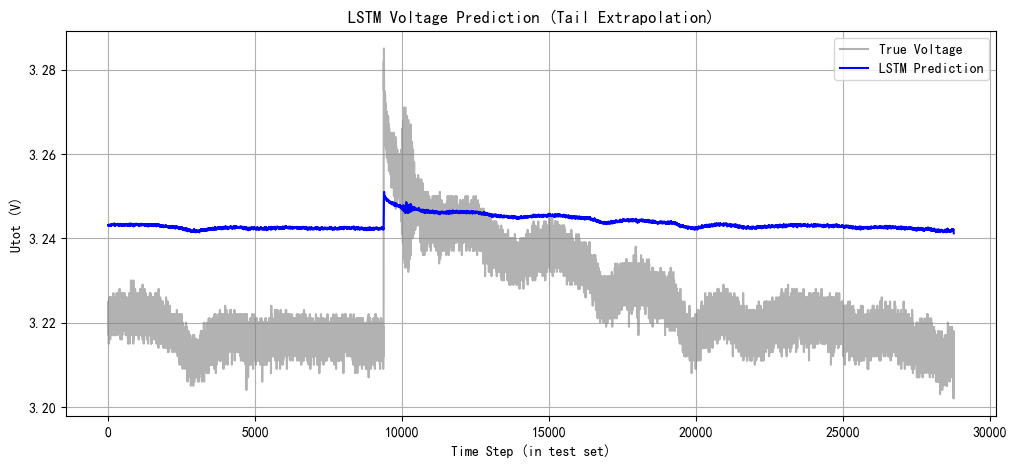

LSTM 测试集 RMSE: 0.021278 V


In [8]:
# 1. 测试阶段
model.eval() # 开启测试模式
with torch.no_grad(): # 测试时不需要计算梯度，节省内存
    predictions = model(X_test_tensor)

# 2. 反归一化（我们之前把 3.3V 变成了 0.1，现在要变回来才能和真实值比）
predictions_real = scaler.inverse_transform(predictions.numpy())
y_test_real = scaler.inverse_transform(y_test_tensor.numpy())

# 3. 画图对比
plt.figure(figsize=(12, 5))
# 画真实的后 20% 数据
plt.plot(range(len(y_test_real)), y_test_real, label='True Voltage', color='gray', alpha=0.6)
# 画 LSTM 预测的数据
plt.plot(range(len(predictions_real)), predictions_real, label='LSTM Prediction', color='blue')
plt.xlabel('Time Step (in test set)')
plt.ylabel('Utot (V)')
plt.title('LSTM Voltage Prediction (Tail Extrapolation)')
plt.legend()
plt.grid(True)
#plt.savefig(r'C:\Users\YOGA\Desktop\神经学习v1', dpi=300, bbox_inches='tight')
plt.show()

# 算一下 RMSE
from sklearn.metrics import mean_squared_error
import math
rmse_lstm = math.sqrt(mean_squared_error(y_test_real, predictions_real))
print(f"LSTM 测试集 RMSE: {rmse_lstm:.6f} V")